# 02 · Marmousi FWI with three native PyTorch optimizers

**Goal.** Build one frequency-domain inverse problem, then run `torch.optim.Adam`, `RMSprop`, and `LBFGS` through the same `InversionRunner`. Compare accepted models, data misfit, closure work, and elapsed time.

**Scope.** This is a small, reproducible CPU tutorial using a **31 × 61 crop of Marmousi at the original 25 m spacing**, six sources, 29 receivers, one 3 Hz frequency, and five accepted outer steps per optimizer. The full input model is shown for context. Observations use the same grid, PML, and operator as inversion: this is an **integration demonstration**, not an independent reconstruction-accuracy test or a ranking of optimizers.

**Prerequisites.** Install the repository's `fwi2d` and notebook dependencies following the [README](../README.md), select that Python kernel, and open this notebook from the repository root or `notebooks/`. The cells make no provider calls, install no packages, and save no wavefield history. Use **Restart Kernel → Run All** for a fresh comparison.

| Quantity | Convention |
| :--- | :--- |
| Physical arrays / coordinates | `[z, x]` / `(depth, horizontal position)` in metres |
| Velocity / model parameter | $v$ in m/s; $m=1/v^2$ in s²/m² |
| Data axes | `[frequency, source, receiver]` |
| Precision and solver | CPU float64 / complex128; sparse direct reference solver |
| Sources | Unit normalized point-source strengths, not calibrated pressure in Pa |

## Setup · reproducible environment

Fix the seed and CPU thread count, locate the checkout without an absolute machine path, and use a consistent plotting style. Timings are measured in this notebook and vary with hardware and other running work.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import time

import numpy as np
import pandas as pd
import torch
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "simplefwi/fwi2d").is_dir()
             and (p / "data/marmousi.mat").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the SimpleFWI checkout or notebooks/.")
sys.path.insert(0, str(ROOT))
from simplefwi.fwi2d import (
    AcousticFWI, Acquisition, BoundaryConfig, Grid2D, SolverConfig,
    VelocityParameters, InversionRunner, assess_dispersion, load_marmousi,
)

SEED = 17
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
COLORS = {"Adam": "#0072B2", "RMSprop": "#D55E00", "LBFGS": "#009E73"}
MARKERS = {"Adam": "o", "RMSprop": "s", "LBFGS": "^"}
print(json.dumps({"python": platform.python_version(), "python_executable": sys.executable, "torch": str(torch.__version__),
                  "device": "cpu", "model_dtype": "float64", "wave_dtype": "complex128",
                  "torch_threads": torch.get_num_threads(), "seed": SEED}, indent=2))

{
  "python": "3.12.14",
  "python_executable": "/workspace/SimpleFWI/.venv/bin/python",
  "torch": "2.12.0+cpu",
  "device": "cpu",
  "model_dtype": "float64",
  "wave_dtype": "complex128",
  "torch_threads": 1,
  "seed": 17
}


## Step 1 · select a physical Marmousi window

`load_marmousi(..., velocity_unit="m/s")` makes the source units explicit. Keep the original sample spacing and translate the crop origin; do not relabel a cropped array as starting at zero. Index slices below are half-open. We display the complete supplied model but **solve only the highlighted crop**.

The starting model is a Gaussian-smoothed version of the cropped truth, multiplied by 0.97. The smoothing standard deviation is three cells (75 m) in each direction. This deliberately accessible synthetic initial model is not an estimate recovered from field data. All crop cells are active; velocity bounds are 1400–6500 m/s.

Dataset SHA256: 6756a104e3e5eb641ba4ba05c7fb983978e13c9885fac87c4909e51a79cad572
Full input: (121, 373); crop: (31, 61); spacing: (25.0, 25.0) m
Crop coordinates: x=2800…4300 m; z=500…1250 m


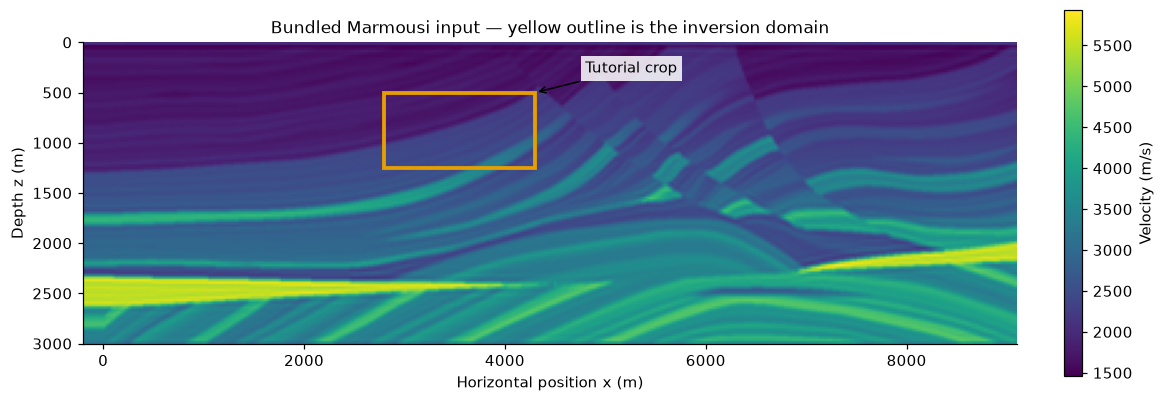

In [2]:
data_path = ROOT / "data/marmousi.mat"
dataset_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
full_grid, full_velocity = load_marmousi(data_path, velocity_unit="m/s")
z_slice, x_slice = slice(20, 51), slice(120, 181)
true_velocity = full_velocity[z_slice, x_slice].clone()
grid = Grid2D(
    tuple(true_velocity.shape), full_grid.spacing_m,
    (full_grid.origin_m[0] + z_slice.start * full_grid.spacing_m[0],
     full_grid.origin_m[1] + x_slice.start * full_grid.spacing_m[1]),
)
initial_velocity = torch.tensor(
    0.97 * gaussian_filter(true_velocity.numpy(), sigma=(3, 3), mode="reflect"),
    dtype=torch.float64,
)
BOUNDS = (1400.0, 6500.0)
FREQUENCIES_HZ = (3.0,)
BATCH_SIZE = 2
OUTER_STEPS = 5
z = grid.origin_m[0] + np.arange(grid.shape[0]) * grid.spacing_m[0]
x = grid.origin_m[1] + np.arange(grid.shape[1]) * grid.spacing_m[1]
extent = (x[0], x[-1], z[-1], z[0])
full_extent = (
    full_grid.origin_m[1], full_grid.origin_m[1] + (full_grid.shape[1]-1)*full_grid.spacing_m[1],
    full_grid.origin_m[0] + (full_grid.shape[0]-1)*full_grid.spacing_m[0], full_grid.origin_m[0],
)
print("Dataset SHA256:", dataset_sha256)
print(f"Full input: {full_grid.shape}; crop: {grid.shape}; spacing: {grid.spacing_m} m")
print(f"Crop coordinates: x={x[0]:.0f}…{x[-1]:.0f} m; z={z[0]:.0f}…{z[-1]:.0f} m")

fig, ax = plt.subplots(figsize=(10.5, 3.8), layout="constrained")
im = ax.imshow(full_velocity.numpy(), extent=full_extent, cmap="viridis", aspect="equal")
ax.add_patch(Rectangle((x[0], z[0]), x[-1]-x[0], z[-1]-z[0],
                       fill=False, edgecolor="#E69F00", linewidth=2.5))
ax.annotate("Tutorial crop", xy=(x[-1], z[0]), xytext=(x[-1]+500, z[0]-200),
            arrowprops={"arrowstyle": "->", "color": "black"}, fontsize=10,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": .85, "pad": 3})
ax.set(xlabel="Horizontal position x (m)", ylabel="Depth z (m)",
       title="Bundled Marmousi input — yellow outline is the inversion domain")
fig.colorbar(im, ax=ax, label="Velocity (m/s)", shrink=.9)
plt.show()

*Figure 1. The full supplied Marmousi velocity field and the fixed physical crop. Cropping changes the external geology seen by a wave: this experiment does not reproduce full-domain Marmousi observations.*

## Step 2 · fix the acquisition, PML, and admissible frequency

Place sources 50 m below the crop top and receivers 75 m below it, away from the physical side edges. Sources and receivers are interpolated at their stated metre coordinates. PML adds **32 cells = 800 m on each side**; the nearest physical velocity is continued into that padding. `top="pml"` represents an absorbing top. An optional `top="free_surface"` imposes zero pressure at the crop top, but would place that surface at 500 m here; it is not the Earth's actual surface, so we keep PML for this interior crop.

For $e^{-i\omega t}$, the interior equation is $(\nabla^2+\omega^2m)u=q$ with $\omega=2\pi f$. We screen the second-order stencil at the **minimum allowed velocity**, not just the initial model. Passing this local homogeneous phase-error screen is necessary but does not certify heterogeneous scattering, PML reflection, or reconstruction accuracy.

Worst screened phase-wavenumber error: 0.478% (target ≤1%)
Screened frequency ceiling: 4.308 Hz
Acquisition: 6 sources × 29 receivers
Boundary: four-sided PML; 800 m padding; PML accuracy unvalidated for this crop.


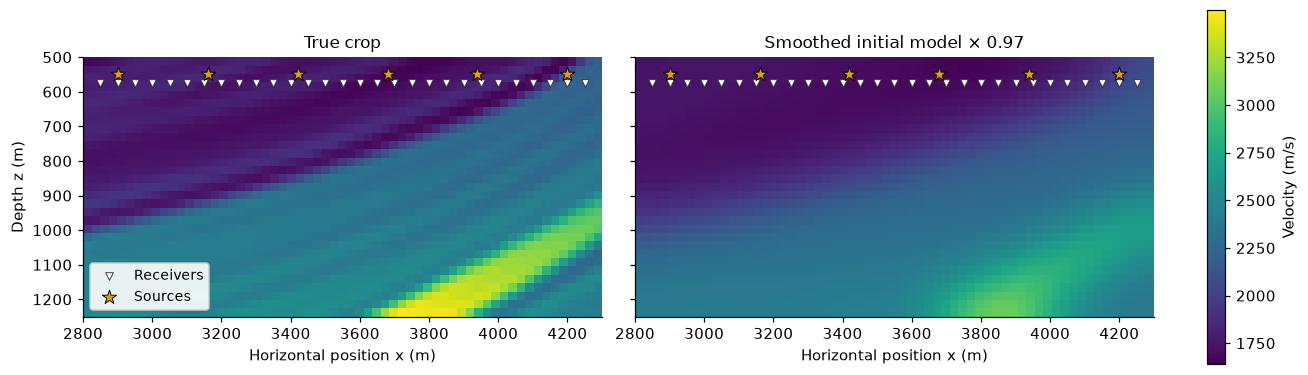

In [3]:
acquisition = Acquisition(
    sources_m=tuple((z[0]+50.0, float(sx)) for sx in np.linspace(x[0]+100, x[-1]-100, 6)),
    receivers_m=tuple((z[0]+75.0, float(rx)) for rx in np.linspace(x[0]+50, x[-1]-50, 29)),
)
boundary = BoundaryConfig(top="pml", pml_cells=32, sigma_max=60.0, alpha=0.0)
solver_config = SolverConfig(
    method="direct", device="cpu", dtype=torch.complex128,
    rtol=1e-10, atol=1e-12, memory_budget_bytes=256*1024**2,
)
screen = assess_dispersion(grid, BOUNDS, FREQUENCIES_HZ, max_phase_error=.01)
assert screen.passed, "Refine the grid or lower the frequency before continuing."
print(f"Worst screened phase-wavenumber error: {100*screen.max_phase_error:.3f}% (target ≤1%)")
print(f"Screened frequency ceiling: {screen.frequency_ceiling_hz:.3f} Hz")
print(f"Acquisition: {len(acquisition.sources_m)} sources × {len(acquisition.receivers_m)} receivers")
print("Boundary: four-sided PML; 800 m padding; PML accuracy unvalidated for this crop.")

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.1), layout="constrained", sharex=True, sharey=True)
vmin, vmax = float(true_velocity.min()), float(true_velocity.max())
sources, receivers = np.array(acquisition.sources_m), np.array(acquisition.receivers_m)
for ax, v, title in zip(axes, (true_velocity, initial_velocity), ("True crop", "Smoothed initial model × 0.97")):
    im = ax.imshow(v.numpy(), extent=extent, cmap="viridis", vmin=vmin, vmax=vmax, aspect="equal")
    ax.scatter(receivers[:,1], receivers[:,0], marker="v", s=25, facecolors="white",
               edgecolors="#333333", linewidths=.6, label="Receivers", zorder=3)
    ax.scatter(sources[:,1], sources[:,0], marker="*", s=95, c="#E69F00",
               edgecolors="black", linewidths=.6, label="Sources", zorder=4)
    ax.set(title=title, xlabel="Horizontal position x (m)")
axes[0].set_ylabel("Depth z (m)")
axes[0].legend(loc="lower left", fontsize=9, framealpha=.9)
fig.colorbar(im, ax=axes, label="Velocity (m/s)", shrink=.8)
plt.show()

*Figure 2. Identical acquisition geometry and colour limits for the true and initial crops. Only the physical domain is shown; the surrounding 800 m PML is omitted. The direct solver's memory budget bounds its own accounted storage; it is not a hard cap on total process memory or transient sparse factorization allocations.*

## Step 3 · generate one fixed dataset and one normalized objective

All three optimizers use exactly the same noiseless observations, source amplitudes, frequency, weights, bounds, and start. Define

$$J(\theta)=\frac{1}{2}\left\|\frac{P u(m(\theta))-d_{\mathrm{obs}}}{\|d_{\mathrm{obs}}\|_2}\right\|_2^2,
\qquad v(\theta)=v_{\min}+(v_{\max}-v_{\min})\operatorname{sigmoid}(\theta),\quad m=v^{-2}.$$

The weight is fixed once; it is not renormalized during optimization or per source. We use **no physical regularizer and no weight decay** to keep the comparison transparent. Production inversion generally needs suitable prior information and continuation. Source batches of two keep one differentiable batch at a time; numeric CPU factors can be reused within a fixed model and frequency.

Observed data: (1, 6, 29) [frequency, source, receiver], torch.complex128
Initial J = 0.0040678957; initial model RMSE = 143.62 m/s
Maximum forward relative linear residual = 1.032e-14


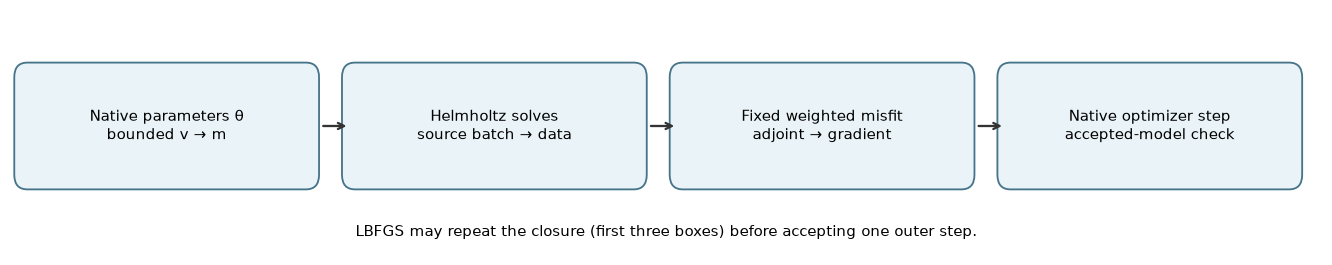

In [4]:
problem = AcousticFWI(grid, acquisition, boundary, solver_config)
observed = problem.simulate(true_velocity, FREQUENCIES_HZ, source_batch_size=BATCH_SIZE)
weight = 1.0 / float(torch.linalg.vector_norm(observed))
objective = problem.objective(observed, FREQUENCIES_HZ, weights=weight)
with torch.no_grad():
    initial_loss = float(objective.loss(initial_velocity.reciprocal().square(),
                                       source_batch_size=BATCH_SIZE))
initial_rmse = float(torch.sqrt((initial_velocity-true_velocity).square().mean()))
assert initial_loss > 0 and np.isfinite(initial_loss)
max_forward_residual = max(r.relative_residual for r in problem.last_solve_reports)
print(f"Observed data: {tuple(observed.shape)} [frequency, source, receiver], {observed.dtype}")
print(f"Initial J = {initial_loss:.8g}; initial model RMSE = {initial_rmse:.2f} m/s")
print(f"Maximum forward relative linear residual = {max_forward_residual:.3e}")

fig, ax = plt.subplots(figsize=(12, 2.3), layout="constrained")
ax.set(xlim=(0, 12), ylim=(0, 2)); ax.axis("off")
labels = ["Native parameters θ\nbounded v → m", "Helmholtz solves\nsource batch → data",
          "Fixed weighted misfit\nadjoint → gradient", "Native optimizer step\naccepted-model check"]
for i, label in enumerate(labels):
    left = .15 + 3*i
    ax.add_patch(FancyBboxPatch((left, .65), 2.55, .8, boxstyle="round,pad=.12",
                               facecolor="#EAF3F7", edgecolor="#46748A", linewidth=1.2))
    ax.text(left+1.275, 1.05, label, ha="center", va="center", fontsize=10)
    if i < 3:
        ax.annotate("", xy=(left+2.95, 1.05), xytext=(left+2.68, 1.05),
                    arrowprops={"arrowstyle": "->", "lw": 1.5, "color": "#333333"})
ax.text(6, .18, "LBFGS may repeat the closure (first three boxes) before accepting one outer step.",
        ha="center", va="center", fontsize=10)
plt.show()

*Figure 3. Native optimizer integration. The runner accumulates physical gradients across batches and then applies one parameterization pullback. After a step, it evaluates the loss at the final parameters; an LBFGS trial loss is never reported as the accepted loss. A small linear residual verifies the discrete equation solve, not the physical accuracy of the experiment.*

## Step 4 · run Adam, RMSprop, and LBFGS

The notebook constructs native `torch.optim` objects directly. `VelocityParameters` enforces the same smooth velocity bounds for all three; `InversionRunner` supplies the deterministic closure and accepted-step lifecycle.

The selected learning rates make this short fixture useful to inspect, **not equally tuned or generally optimal**. RMSprop uses a smaller learning rate because its adaptive denominator produces a different step scale. LBFGS uses strong Wolfe search, up to five internal iterations per outer step, and a five-vector history. Five outer steps therefore need not represent the same computational work. The runner also recomputes one forward-only accepted loss after each outer step; those checks are timed but are not closure evaluations.

Each run starts with fresh parameters, native optimizer state, and an empty solver cache. Timing includes each `runner.step()` and its accepted-loss check, but excludes shared observation generation and plotting.

In [5]:
recipes = {
    "Adam": dict(lr=.03, weight_decay=0.0),
    "RMSprop": dict(lr=.003, weight_decay=0.0),
    "LBFGS": dict(lr=1.0, max_iter=5, history_size=5,
                  line_search_fn="strong_wolfe", tolerance_grad=1e-10,
                  tolerance_change=1e-12),
}
results = {}
for name, kwargs in recipes.items():
    problem.solver.clear_cache()
    model = VelocityParameters(initial_velocity.clone(), BOUNDS)
    optimizer = getattr(torch.optim, name)(model.parameters(), **kwargs)
    runner = InversionRunner(objective, model, optimizer, source_batch_size=BATCH_SIZE)
    rows = [{"step": 0, "loss": initial_loss, "closures": 0, "seconds": 0.0}]
    start = time.perf_counter()
    for _ in range(OUTER_STEPS):
        accepted = runner.step()
        rows.append({"step": accepted.accepted_step, "loss": accepted.loss,
                     "closures": runner.closure_evaluations,
                     "seconds": time.perf_counter()-start})
    final_velocity = model.velocity().detach().clone()
    results[name] = {"history": pd.DataFrame(rows), "velocity": final_velocity,
                     "optimizer": optimizer, "runner": runner,
                     "rmse": float(torch.sqrt((final_velocity-true_velocity).square().mean()))}
    print(f"{name:7s}: J/J₀={rows[-1]['loss']/initial_loss:.5f}; "
          f"{rows[-1]['closures']:2d} closures; {rows[-1]['seconds']:.2f} s")
problem.solver.clear_cache()

Adam   : J/J₀=0.16604;  5 closures; 1.14 s


RMSprop: J/J₀=0.14905;  5 closures; 1.13 s


LBFGS  : J/J₀=0.00168; 30 closures; 6.13 s


## Step 5 · compare loss and work before comparing models

Every plotted curve uses the same initial objective `initial_loss`. Points are **accepted outer states**, not the trial models evaluated inside an LBFGS line search. Wall time is the most inclusive of these three work axes, though a single small run is not a performance benchmark.

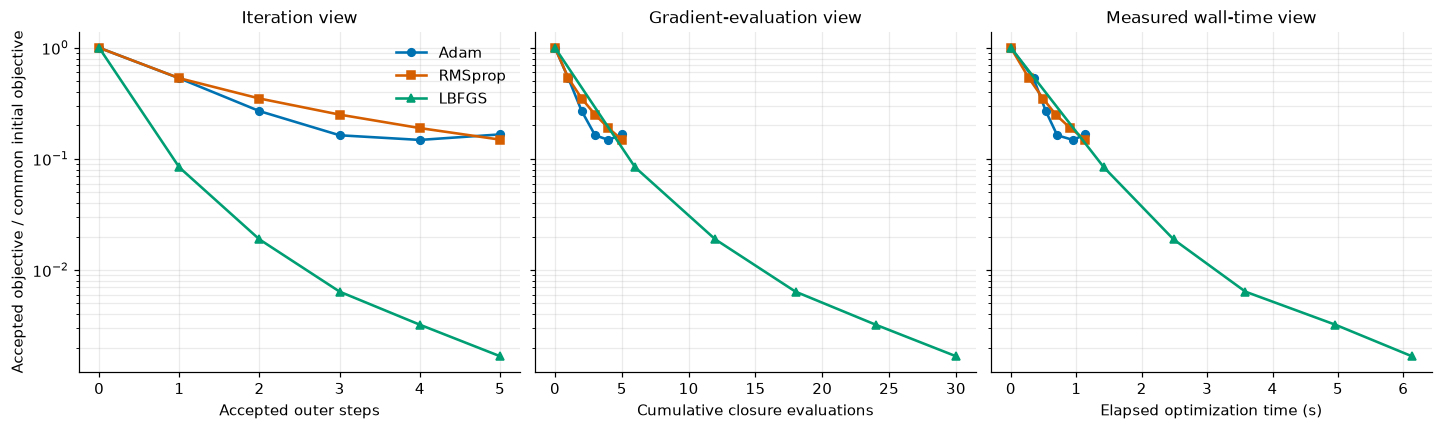

,accepted steps,closures,accepted loss checks,final J,final J / J₀,RMSE (m/s),time (s)
optimizer,,,,,,,
Adam,5,5,5,0.000675418,0.16604,137.78,1.14
RMSprop,5,5,5,0.000606316,0.14905,134.41,1.13
LBFGS,5,30,5,6.81685e-06,0.00168,128.37,6.13


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained", sharey=True)
for name, result in results.items():
    history = result["history"]
    for ax, horizontal in zip(axes, ("step", "closures", "seconds")):
        ax.semilogy(history[horizontal], history["loss"]/initial_loss,
                    marker=MARKERS[name], color=COLORS[name], linewidth=1.7,
                    markersize=5, label=name)
for ax, label in zip(axes, ("Accepted outer steps", "Cumulative closure evaluations", "Elapsed optimization time (s)")):
    ax.set_xlabel(label); ax.grid(alpha=.25, which="both")
axes[0].set_ylabel("Accepted objective / common initial objective")
axes[0].legend(frameon=False)
axes[0].set_title("Iteration view")
axes[1].set_title("Gradient-evaluation view")
axes[2].set_title("Measured wall-time view")
plt.show()

metrics = pd.DataFrame([
    {"optimizer": name, "accepted steps": int(r["history"].iloc[-1]["step"]),
     "closures": int(r["history"].iloc[-1]["closures"]),
     "accepted loss checks": OUTER_STEPS,
     "final J": float(r["history"].iloc[-1]["loss"]),
     "final J / J₀": float(r["history"].iloc[-1]["loss"])/initial_loss,
     "RMSE (m/s)": r["rmse"], "time (s)": float(r["history"].iloc[-1]["seconds"])}
    for name, r in results.items()
]).set_index("optimizer")
display(metrics.style.format({"final J": "{:.6g}", "final J / J₀": "{:.5f}",
                              "RMSE (m/s)": "{:.2f}", "time (s)": "{:.2f}"}))

*Figure 4 and table. All methods reduce the initial objective in this run. Adam can rise after a previous accepted state: acceptance checks numerical validity and the final objective, not monotonic descent. LBFGS uses substantially more closures, so its smaller loss after five outer steps is not an equal-work victory. Model RMSE is available only because this synthetic example knows the truth.*

## Step 6 · inspect spatial changes and a velocity profile

The upper row uses common velocity limits; the lower row uses one symmetric scale for all signed errors, including the initial model. A single low frequency and limited surface aperture constrain only part of the model. A good data fit does not recover every layer or prove uniqueness.

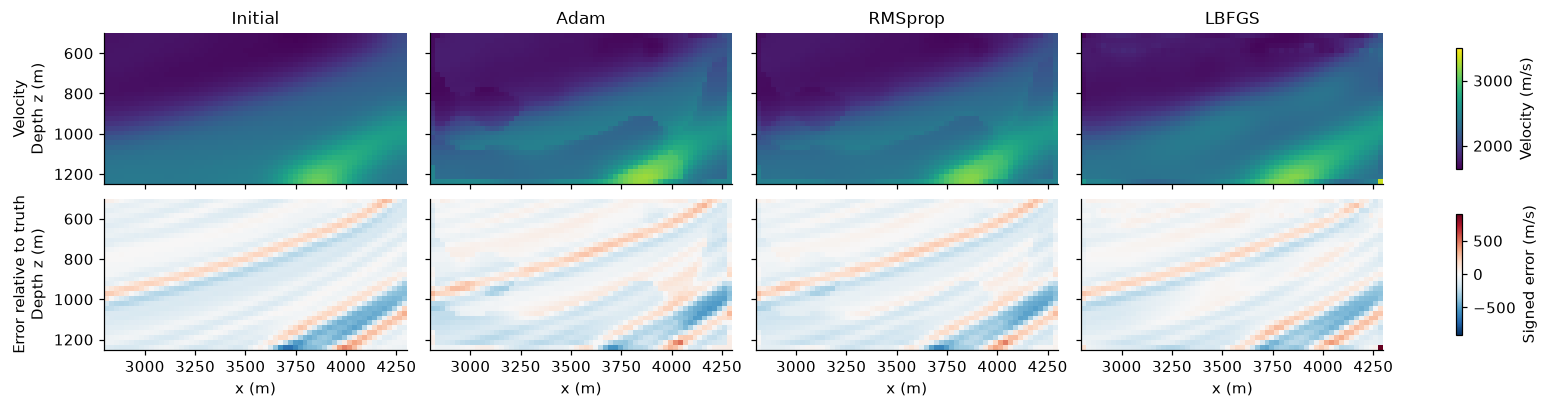

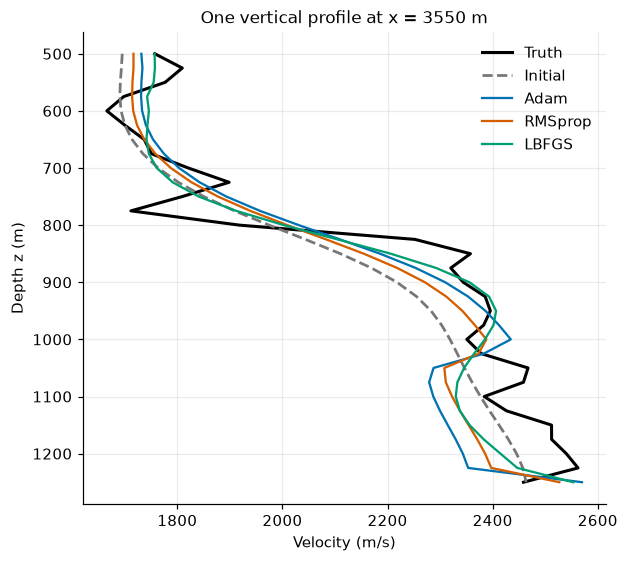

In [7]:
models = {"Initial": initial_velocity, **{name: r["velocity"] for name, r in results.items()}}
error_limit = max(float((v-true_velocity).abs().max()) for v in models.values())
fig, axes = plt.subplots(2, 4, figsize=(14, 4.8), layout="compressed", sharex=True, sharey=True)
for column, (name, velocity) in enumerate(models.items()):
    vi = axes[0, column].imshow(velocity.numpy(), extent=extent, cmap="viridis",
                                vmin=vmin, vmax=vmax, aspect="equal")
    ei = axes[1, column].imshow((velocity-true_velocity).numpy(), extent=extent,
                                cmap="RdBu_r", vmin=-error_limit, vmax=error_limit, aspect="equal")
    axes[0, column].set_title(name)
    axes[1, column].set_xlabel("x (m)")
axes[0, 0].set_ylabel("Velocity\nDepth z (m)")
axes[1, 0].set_ylabel("Error relative to truth\nDepth z (m)")
fig.colorbar(vi, ax=axes[0, :], label="Velocity (m/s)", shrink=.8)
fig.colorbar(ei, ax=axes[1, :], label="Signed error (m/s)", shrink=.8)
plt.show()

profile_index = grid.shape[1] // 2
fig, ax = plt.subplots(figsize=(5.6, 5), layout="constrained")
ax.plot(true_velocity[:, profile_index], z, color="black", lw=2, label="Truth")
ax.plot(initial_velocity[:, profile_index], z, color="#777777", lw=1.8, ls="--", label="Initial")
for name, r in results.items():
    ax.plot(r["velocity"][:, profile_index], z, color=COLORS[name], lw=1.5, label=name)
ax.invert_yaxis()
ax.set(xlabel="Velocity (m/s)", ylabel="Depth z (m)", title=f"One vertical profile at x = {x[profile_index]:.0f} m")
ax.grid(alpha=.25); ax.legend(frameon=False)
plt.show()

*Figures 5–6. Accepted final models, signed model errors, and one vertical profile. Fine-scale differences remain even when the data misfit falls sharply. No method is selected as a universal winner; changing regularization, acquisition, frequency, starting model, or step budget can change the comparison.*

## Checks · reproducibility and numerical validity

These checks verify the tutorial's contracts: native optimizer classes, shared data and objective, five accepted states, finite results, physical bounds, and an overall loss reduction. They do not assert monotonic Adam/RMSprop loss or treat same-grid observations as independent physical validation.

In [8]:
for name, result in results.items():
    assert type(result["optimizer"]) is getattr(torch.optim, name)
    assert result["runner"].objective is objective
    assert result["runner"].accepted_steps == OUTER_STEPS
    assert torch.isfinite(result["velocity"]).all()
    assert bool((result["velocity"] > BOUNDS[0]).all())
    assert bool((result["velocity"] < BOUNDS[1]).all())
    assert np.isfinite(result["history"][["loss", "seconds"]].to_numpy()).all()
    assert 0 <= result["history"].iloc[-1]["loss"] < initial_loss
assert tuple(observed.shape) == (1, 6, 29)
assert max_forward_residual < 1e-10
assert grid.origin_m == (500.0, 2800.0) and grid.spacing_m == (25.0, 25.0)
print("PASS: native optimizers, accepted-step counts, finite bounded models, and overall loss reduction.")
print("Validation class: same-grid cropped Marmousi optimizer/PDE integration.")
print("Not established: independent PML/heterogeneous accuracy, full-domain recovery, or optimizer superiority.")

PASS: native optimizers, accepted-step counts, finite bounded models, and overall loss reduction.
Validation class: same-grid cropped Marmousi optimizer/PDE integration.
Not established: independent PML/heterogeneous accuracy, full-domain recovery, or optimizer superiority.


## Next steps · expand the experiment deliberately

1. Repeat each recipe under a common wall-time or closure-work budget, then tune learning rates and report multiple initial models. Keep accepted-loss checks in timing totals.
2. Add a physical regularizer and noise model with explicit units; the objective's normalization is not a measured noise precision. Validate against observations generated independently of this discretization.
3. Use a coarse-to-fine frequency schedule only after dispersion and PML checks. Construct a fresh optimizer when grid/parameter dimension changes; do not reuse LBFGS history across incompatible stages.
4. For larger Marmousi runs or a CUDA comparison, start with [Notebook 01](01_helmholtz_marmousi_cpu_gpu.ipynb). Raising frequency or selecting CUDA is not an automatic accuracy or speed guarantee.
5. For local curvature and uncertainty, continue to [Notebook 03](03_camembert_hessian_uncertainty.ipynb). Data fit alone does not quantify posterior uncertainty.

For optional archival output, see [accepted-state recording](../guides/outputs.md) and [native optimizer recipes](../guides/optimizers.md). Attach `AcceptedStateRecorder` to `InversionRunner(..., accepted_callbacks=(adapter,))` and select a modest array cadence. Recording inside a closure would confuse LBFGS trial states with accepted iterations. This notebook keeps only scalar histories and one final model per optimizer; its native optimizer state remains available in `results` until you delete it or restart the kernel.